# 01 – Dataset Audit & EDA · SemEval-2027 Task 8 (StereoQueerEval)

**Phạm vi đồ án:** Subtask A (stereotype, nhị phân) + Subtask B (hate speech, 3 lớp), **English**.
Notebook vẫn đọc cả IT/NL và nhãn `target` (Subtask C) vì chúng có ích cho các quyết định sau này
(dùng thêm dữ liệu đa ngôn ngữ? học đa nhiệm với `target` làm nhiệm vụ phụ?).

**Các thông tin chính thức cần nhớ** (theo *Guidelines for Participants v1*, 18/09/2026):

| Điểm | Nội dung |
|---|---|
| Metric | **Macro-F1**, tính riêng cho từng subtask (A: 2 lớp, B: 3 lớp có trọng số bằng nhau) |
| Test | EN 743 · IT 597 · NL 554 · FA 1.654 (chỉ có test); ra mắt tháng 01/2027 |
| Train/test | **lấy từ các video YouTube khác nhau** → validation phải chia theo video |
| Baseline chính thức | random · majority · Qwen2.5-7B-Instruct zero-shot |
| Input | được dùng cả `yt_title`, `yt_description`, `yt_comment` |

**Notebook này trả lời:** schema & chất lượng dữ liệu → phân bố nhãn → quan hệ A–B(–C) → cấu trúc video/context
→ độ dài (theo token thật) → đặc trưng bề mặt & từ vựng phân biệt → ví dụ mơ hồ/nhiễu nhãn
→ so sánh EN/IT/NL → **tạo split validation theo video** (lưu file để các notebook sau dùng chung).

> ⚠️ **Cảnh báo nội dung:** dữ liệu chứa ngôn từ xúc phạm, kỳ thị đối với người LGBTQIA+, được giữ nguyên để nghiên cứu.

## 0. Cấu hình

In [1]:
import re, json, csv, unicodedata, warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from scipy.stats import chi2_contingency
from sklearn.metrics import f1_score, normalized_mutual_info_score

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 140)
pd.set_option("display.width", 220)
pd.set_option("display.max_rows", 120)

# Đổi DATA_DIR nếu dữ liệu nằm chỗ khác
PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = PROJECT_DIR.parent / "StereoQueerEval_SemEval-2027" / "StereoQueerEval_training"
OUT_DIR = PROJECT_DIR / "outputs" / "eda"
FIG_DIR = OUT_DIR / "figures"
SPLIT_DIR = PROJECT_DIR / "data" / "splits"
for d in (FIG_DIR, SPLIT_DIR):
    d.mkdir(parents=True, exist_ok=True)

LANGS = ["EN", "IT", "NL"]
MAIN = "EN"
SEED = 42
EXPECTED = {"EN": (2989, 743), "IT": (2400, 597), "NL": (2238, 554)}   # (train, test) theo guideline v1
COLS = ["StereoQueerEval_id", "yt_title", "yt_description", "yt_comment", "stereotype", "hate_speech", "target"]
TEXT_COLS = ["yt_title", "yt_description", "yt_comment"]
A_LABELS = ["no", "yes"]
B_LABELS = ["no", "yes_implicit", "yes_explicit"]
IDENTITIES = ["l", "g", "b", "t", "q", "i", "a", "nb", "lgbtqia+"]
SUMMARY = {}   # các con số chính, lưu ra JSON ở cuối notebook

print("DATA_DIR  :", DATA_DIR, "| tồn tại:", DATA_DIR.exists())
print("OUTPUT    :", OUT_DIR)

DATA_DIR  : C:\Users\Public\Documents\NĂM 3\NLP\StereoQueerEval_SemEval-2027\StereoQueerEval_training | tồn tại: True
OUTPUT    : C:\Users\Public\Documents\NĂM 3\NLP\SemEval2027_Task8\outputs\eda


In [2]:
# ---- Style biểu đồ: palette phân loại cố định theo thứ tự, lưới mảnh, chữ dùng màu mực (không dùng màu series)
INK, INK2, MUTED, GRID, SURF = "#0b0b0b", "#52514e", "#8a8984", "#e6e5e1", "#fcfcfb"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
COL_A = dict(zip(A_LABELS, SERIES[:2]))          # no = xanh, yes = cam
COL_B = dict(zip(B_LABELS, SERIES[:3]))          # no = xanh, implicit = cam, explicit = xanh ngọc
COL_LANG = dict(zip(LANGS, SERIES[:3]))
BLUES = mpl.colors.LinearSegmentedColormap.from_list(
    "seq_blue", ["#f3f8fe", "#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"])

plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": GRID, "axes.linewidth": 1, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 1,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.titlesize": 12, "axes.titleweight": "semibold", "axes.titlelocation": "left", "axes.titlecolor": INK,
    "axes.labelsize": 10, "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.frameon": False,
    "legend.fontsize": 9, "lines.linewidth": 2, "figure.dpi": 110,
})


def savefig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def hbar(ax, labels, values, colors, notes=None, fmt="{:,}"):
    # Thanh ngang mảnh, nhãn giá trị ở đầu thanh (màu mực)
    y = np.arange(len(labels))
    ax.barh(y, values, height=0.5, color=colors, zorder=2)
    ax.set_yticks(y, labels)
    ax.invert_yaxis()
    ax.yaxis.grid(False)
    ax.tick_params(axis="y", length=0)
    notes = notes or [""] * len(values)
    for yi, v, n in zip(y, values, notes):
        ax.text(v, yi, f"  {fmt.format(v)}" + (f"  ({n})" if n else ""), va="center", color=INK2, fontsize=9)
    ax.set_xlim(0, max(values) * 1.3)


def annotated_heatmap(ax, mat, row_labels, col_labels, cell_text, cmap=BLUES, vmax=None):
    im = ax.imshow(mat, cmap=cmap, vmin=0, vmax=vmax if vmax is not None else mat.max(), aspect="auto")
    ax.set_xticks(range(len(col_labels)), col_labels)
    ax.set_yticks(range(len(row_labels)), row_labels)
    ax.grid(False)
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
    norm = im.norm
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            r, g, b, _ = cmap(norm(mat[i, j]))
            lum = 0.2126 * r + 0.7152 * g + 0.0722 * b
            ax.text(j, i, cell_text[i][j], ha="center", va="center", fontsize=9,
                    color="white" if lum < 0.5 else INK)
    return im

## 1. Dataset audit

### 1.1 Đọc file & kiểm tra schema

README cảnh báo: title/description/comment **có thể chứa xuống dòng bên trong trường có dấu ngoặc kép** →
phải đọc bằng TSV parser thật (đó là lý do `wc -l` cho ra ~20k dòng dù chỉ có 2.989 mẫu).
Ta đọc bằng `pandas` với `keep_default_na=False` (để chuỗi `"none"`/`"NA"` trong văn bản không bị biến thành NaN),
rồi đối chiếu số bản ghi với module `csv` chuẩn của Python.

In [3]:
def load_lang(lang):
    path = DATA_DIR / f"StereoQueerEval_{lang}_training.tsv"
    df = pd.read_csv(path, sep="\t", dtype=str, keep_default_na=False, encoding="utf-8")
    with open(path, encoding="utf-8", newline="") as f:
        n_csv = sum(1 for _ in csv.reader(f, delimiter="\t")) - 1
    n_lines = path.read_bytes().count(b"\n")
    return df, n_csv, n_lines


raw, audit_rows = {}, []
for lang in LANGS:
    df, n_csv, n_lines = load_lang(lang)
    raw[lang] = df
    audit_rows.append({
        "lang": lang,
        "rows_pandas": len(df),
        "rows_csv_module": n_csv,
        "physical_lines": n_lines,
        "expected_train": EXPECTED[lang][0],
        "expected_test": EXPECTED[lang][1],
        "schema_ok": list(df.columns) == COLS,
        "id_unique": df.StereoQueerEval_id.is_unique,
        "id_format_ok": df.StereoQueerEval_id.str.fullmatch(rf"training_{lang}_\d{{4}}").all(),
    })
audit = pd.DataFrame(audit_rows).set_index("lang")
display(audit)
print("Cột:", COLS)
assert (audit.rows_pandas == audit.rows_csv_module).all() and (audit.rows_pandas == audit.expected_train).all()

,rows_pandas,rows_csv_module,physical_lines,expected_train,expected_test,schema_ok,id_unique,id_format_ok
lang,,,,,,,,
EN,2989,2989,20667,2989,743,True,True,True
IT,2400,2400,25002,2400,597,True,True,True
NL,2238,2238,25718,2238,554,True,True,True


Cột: ['StereoQueerEval_id', 'yt_title', 'yt_description', 'yt_comment', 'stereotype', 'hate_speech', 'target']


### 1.2 Gán `video_id`

Dữ liệu không có ID video. Mỗi `yt_title` ứng với một video → ta gán `video_id` theo title đã chuẩn hoá.
Nếu một title đi kèm nhiều description (có thể là cùng video nhưng description bị sửa), ta **vẫn gộp chung một nhóm**
— gộp thừa thì an toàn hơn tách thiếu khi chống rò rỉ giữa train/validation.

In [4]:
def norm_title(s):
    return re.sub(r"\s+", " ", unicodedata.normalize("NFKC", s).strip().lower())


for lang, df in raw.items():
    df.insert(0, "lang", lang)
    codes = pd.factorize(df.yt_title.map(norm_title))[0]
    df["video_id"] = [f"{lang}_v{c:03d}" for c in codes]

data = pd.concat(raw.values(), ignore_index=True)

multi_desc = (data.groupby(["lang", "video_id"]).yt_description.nunique().loc[lambda s: s > 1])
print("Số title có >1 description:", len(multi_desc))
display(data[data.video_id.isin(multi_desc.index.get_level_values(1))]
        .groupby(["video_id", "yt_title"]).yt_description.apply(lambda s: [d[:90] + "…" for d in s.unique()]))

Số title có >1 description: 3


video_id  yt_title                                                                                           
EN_v078   Trump mocks transgender athletes in women's sports | [CHANNEL]                                         [President Trump mocks transgender athletes while addressing Republican members of the U.S.…, US President Donald Trump mocked transgend...
EN_v098   Dear Mamma: a transgender man, his mother and their journey in letters                                 [When Naissa tells his mother Daniela that he identifies as a trans man she struggles to un…, When Naissa tells his mother Daniela that ...
IT_v055   Ddl Zan, Dario e Andrea gay e cattolici: "Quella del Concordato mossa disperata, la Chiesa è altro"    [Andrea e Dario sono sposati da diversi anni e hanno tre figli. Andrea è anche portavoce di…, Andrea e Dario sono sposati da diversi ann...
Name: yt_description, dtype: object

### 1.3 Thiếu dữ liệu, trường rỗng, ký tự lạ

In [5]:
EMOJI_RE = r"[\U0001F000-\U0001FAFF\u2600-\u27BF\u2B00-\u2BFF]"
checks = {
    "rỗng / chỉ khoảng trắng": lambda s: s.str.strip() == "",
    "chuỗi NA/nan/null": lambda s: s.str.strip().str.lower().isin(["na", "nan", "null", "none", "n/a"]),
    "khoảng trắng đầu/cuối": lambda s: s != s.str.strip(),
    "có \\r (CRLF)": lambda s: s.str.contains("\r", regex=False),
    "có xuống dòng": lambda s: s.str.contains("\n", regex=False),
    "HTML entity (&amp; …)": lambda s: s.str.contains(r"&(?:amp|quot|lt|gt|#\d+);"),
    "mojibake (Ã, â€)": lambda s: s.str.contains(r"Ã|â€|Â"),
}
rows = []
for lang, df in raw.items():
    for col in TEXT_COLS:
        rows.append({"lang": lang, "field": col, **{k: int(f(df[col]).sum()) for k, f in checks.items()}})
quality = pd.DataFrame(rows).set_index(["lang", "field"])
display(quality)

label_missing = data.groupby("lang")[["stereotype", "hate_speech", "target"]].agg(lambda s: (s.str.strip() == "").sum())
print("Nhãn rỗng theo ngôn ngữ:"); display(label_missing)

rỗng / chỉ khoảng trắng  chuỗi NA/nan/null  khoảng trắng đầu/cuối  có \r (CRLF)  có xuống dòng  HTML entity (&amp; …)  mojibake (Ã, â€)
lang field                                                                                                                                                  
EN   yt_title                              0                  0                      0             0              0                      0                 0
     yt_description                        0                  0                      0          1786           1786                      0                 0
     yt_comment                            0                  0                      0           351            351                      0                 0
IT   yt_title                              0                  0                      0             0              0                      0                 0
     yt_description                        0                  0                      0          2280           2280                      0                 0
     yt_comment                            0                  0                      0           261            261                      0                 0
NL   yt_title                              0                  0                      0             0              0                      0                 0
     yt_description                        0                  0                      0          2082           2082                      0                 0
     yt_comment                            0                  0                      0           209            209                      0                 0

Nhãn rỗng theo ngôn ngữ:


,stereotype,hate_speech,target
lang,,,
EN,0,0,0
IT,0,0,0
NL,0,0,0


**Đọc bảng trên:** không có trường rỗng, không có khoảng trắng thừa, không lỗi encoding. Vấn đề duy nhất là *định dạng*:
mọi xuống dòng đều là `\r\n` (CRLF) — gần như mọi description và ~12% comment có xuống dòng.
Khi tiền xử lý chỉ cần chuẩn hoá `\r\n → \n`, **không cần bỏ mẫu nào**.
Với `yt_title`, cột "chuỗi NA/nan/null" phải bằng 0 — nếu khác 0 thì đó là văn bản thật chứ không phải giá trị thiếu
(nhờ `keep_default_na=False`).

### 1.4 Placeholder ẩn danh hoá & các token đặc biệt

In [6]:
rows = []
for lang, df in raw.items():
    for col in TEXT_COLS:
        ph = df[col].str.findall(r"\[[A-Z_]+\]").explode().dropna().value_counts()
        rows.append({"lang": lang, "field": col,
                     **{f"{k} (lần)": int(v) for k, v in ph.items()},
                     "dòng có emoji": int(df[col].str.contains(EMOJI_RE).sum()),
                     "dòng có http": int(df[col].str.contains("http").sum()),
                     "dòng có @mention": int(df[col].str.contains(r"(?<!\w)@\w").sum())})
placeholders = pd.DataFrame(rows).set_index(["lang", "field"]).fillna(0).astype(int)
display(placeholders)

[CHANNEL] (lần)  dòng có emoji  dòng có http  dòng có @mention  [URL] (lần)  [EMAIL] (lần)  [USER] (lần)
lang field                                                                                                                   
EN   yt_title                   1013              0             0                 0            0              0             0
     yt_description             5378             15             0                 0         7682             48             0
     yt_comment                   95            359             0                 0            6              0             5
IT   yt_title                     16              0             0                 0            0              0             0
     yt_description             2343            777             0                 0         8768           1256             2
     yt_comment                   18            453             0                 0            1              0             0
NL   yt_title                    228              0             0                 0            0              0             0
     yt_description             4429            382             0                 0         8984            779             0
     yt_comment                   43            372             0                 1            2              0             2

Ban tổ chức đã thay tên kênh, URL, user, email bằng `[CHANNEL]`, `[URL]`, `[USER]`, `[EMAIL]`.
Description chứa rất nhiều `[URL]`/`[CHANNEL]` (link subscribe, quảng cáo kênh) → **đây là nhiễu** khi đưa description vào model;
nên xoá các dòng chỉ gồm placeholder/link trước khi ghép context. Emoji xuất hiện ở ~12% comment EN
→ nên chọn tokenizer xử lý được emoji (hoặc thay emoji bằng mô tả chữ, ví dụ thư viện `emoji.demojize`).

### 1.5 Tính hợp lệ của nhãn

Kiểm tra: giá trị nhãn nằm trong tập cho phép; `target` đúng cú pháp `none | (group|individual)_id[,id…]`;
quy tắc **`target = none` ⇔ `hate_speech = no`** (README); thứ tự identity theo chuẩn `l,g,b,t,q,i,a,nb,lgbtqia+`.

In [7]:
ID_ALT = "|".join(re.escape(i) for i in IDENTITIES)
TARGET_RE = re.compile(rf"^(?:none|(?:group|individual)_(?:{ID_ALT})(?:,(?:{ID_ALT}))*)$")


def parse_target(t):
    if t == "none":
        return "none", ()
    scope, ids = t.split("_", 1)
    return scope, tuple(ids.split(","))


data["target_scope"], data["target_ids"] = zip(*data.target.map(parse_target))
data["joint_AB"] = data.stereotype + "|" + data.hate_speech

order_bad = data.target_ids.map(lambda ids: list(ids) != sorted(ids, key=IDENTITIES.index) or len(set(ids)) != len(ids))
label_checks = data.groupby("lang").apply(lambda d: pd.Series({
    "stereotype ∉ {yes,no}": int((~d.stereotype.isin(A_LABELS)).sum()),
    "hate ∉ 3 lớp": int((~d.hate_speech.isin(B_LABELS)).sum()),
    "target sai cú pháp": int((~d.target.str.match(TARGET_RE)).sum()),
    "hate=no nhưng target≠none": int(((d.hate_speech == "no") & (d.target != "none")).sum()),
    "hate=yes nhưng target=none": int(((d.hate_speech != "no") & (d.target == "none")).sum()),
    "identity sai thứ tự/lặp": int(order_bad[d.index].sum()),
}))
display(label_checks)
assert label_checks.drop(columns="identity sai thứ tự/lặp").to_numpy().sum() == 0, "Có nhãn không hợp lệ!"

,"stereotype ∉ {yes,no}",hate ∉ 3 lớp,target sai cú pháp,hate=no nhưng target≠none,hate=yes nhưng target=none,identity sai thứ tự/lặp
lang,,,,,,
EN,0,0,0,0,0,0
IT,0,0,0,0,0,0
NL,0,0,0,0,0,0


Quy tắc logic B → C được dữ liệu tuân thủ tuyệt đối, nên luật hậu xử lý *"B = no ⇒ C = none"* là **an toàn**.
Lưu ý: theo guideline, Subtask C chỉ được chấm trên các mẫu **gold** hateful, nên luật này không ảnh hưởng điểm C chính thức,
nhưng hữu ích khi học đa nhiệm.

### 1.6 Trùng lặp

Kiểm tra 3 mức: trùng ID; trùng nguyên văn comment; trùng sau chuẩn hoá (lowercase, bỏ dấu câu/emoji).
Quan trọng nhất là **các cặp gần trùng nhưng nhãn khác nhau** → ước lượng thô độ nhiễu nhãn.

In [8]:
def norm_text(s):
    s = unicodedata.normalize("NFKC", s).lower()
    s = re.sub(r"[^\w\s]", " ", s)
    return re.sub(r"\s+", " ", s).strip()


data["comment_norm"] = data.yt_comment.map(norm_text)
rows = []
for lang, d in data.groupby("lang"):
    dup_norm = d[d.comment_norm.duplicated(keep=False)]
    conflict = dup_norm.groupby("comment_norm").filter(
        lambda g: g.stereotype.nunique() > 1 or g.hate_speech.nunique() > 1)
    rows.append({"lang": lang,
                 "trùng ID": int(d.StereoQueerEval_id.duplicated().sum()),
                 "trùng (title,desc,comment)": int(d.duplicated(["yt_title", "yt_description", "yt_comment"]).sum()),
                 "trùng comment nguyên văn": int(d.yt_comment.duplicated().sum()),
                 "nhóm trùng sau chuẩn hoá": int(dup_norm.comment_norm.nunique()),
                 "  …trong đó nhãn A/B mâu thuẫn": int(conflict.comment_norm.nunique()),
                 "nhóm trùng cùng 1 video": int(dup_norm.groupby("comment_norm").video_id.nunique().eq(1).sum())})
display(pd.DataFrame(rows).set_index("lang"))

en_dup = data[(data.lang == MAIN) & data.comment_norm.duplicated(keep=False)].sort_values("comment_norm")
print(f"\n{MAIN}: các comment gần trùng (cùng nội dung sau chuẩn hoá):")
display(en_dup[["video_id", "yt_title", "yt_comment", "stereotype", "hate_speech", "target"]])

,trùng ID,"trùng (title,desc,comment)",trùng comment nguyên văn,nhóm trùng sau chuẩn hoá,…trong đó nhãn A/B mâu thuẫn,nhóm trùng cùng 1 video
lang,,,,,,
EN,0,0,0,4,3,0
IT,0,0,1,5,2,0
NL,0,0,0,5,2,0



EN: các comment gần trùng (cùng nội dung sau chuẩn hoá):


,video_id,yt_title,yt_comment,stereotype,hate_speech,target
1419,EN_v077,Outrage at EU country’s homosexuality education bill,I stand with Hungary.,no,yes_implicit,group_lgbtqia+
1809,EN_v076,Hungary’s anti-LGBT law: How should the EU respond? - [CHANNEL] Newsnight,I stand with Hungary 🇷🇸🤝🇭🇺,no,yes_explicit,group_lgbtqia+
833,EN_v196,Watch: Dylan Mulvaney speaks out for first time after Bud Light controversy,She😂😂😂😂,no,yes_implicit,individual_t
2138,EN_v035,Trans Master Sgt. grieves loss of military career,She*,no,yes_implicit,individual_t
252,EN_v102,Mother of transgender teen weighs in ahead of Supreme Court hearing,That’s a man.,yes,yes_explicit,individual_t
1359,EN_v151,Hear from the trans National Guard pilot falsely accused of flying helicopter in fatal collision,That's a man?,yes,yes_implicit,individual_t
96,EN_v073,The culture of coming out on YouTube,Who gives a shit???,no,yes_explicit,group_lgbtqia+
1663,EN_v177,"[CHANNEL]: [CHANNEL] anchor Don Lemon talks coming out, abuse",Who gives a shit,no,yes_implicit,individual_lgbtqia+


**Quan sát:** gần như không có trùng lặp — không cần khử trùng. Nhưng các cặp gần trùng ở EN rất đáng chú ý:
cùng một câu (ví dụ *"That's a man"*, *"Who gives a shit"*, *"I stand with Hungary"*) có lúc là `yes_implicit`, có lúc `yes_explicit`,
tuỳ **video** và cách viết (dấu `?`, emoji). Nghĩa là:

1. ranh giới **implicit ↔ explicit** phụ thuộc vào ngữ cảnh và có độ nhiễu chú thích nhất định → đây sẽ là cặp lớp khó nhất;
2. context video là thông tin thật sự cần (cùng một câu, khác video → khác nhãn).

## 2. Phân bố nhãn Subtask A & B

In [9]:
en = data[data.lang == MAIN].copy()


def dist_table(df, col, labels):
    out = {}
    for lang, d in df.groupby("lang"):
        vc = d[col].value_counts().reindex(labels, fill_value=0)
        out[(lang, "n")] = vc
        out[(lang, "%")] = (vc / vc.sum() * 100).round(1)
    t = pd.DataFrame(out)
    t.columns = pd.MultiIndex.from_tuples(t.columns)
    return t


print("Subtask A – stereotype"); display(dist_table(data, "stereotype", A_LABELS))
print("Subtask B – hate_speech"); display(dist_table(data, "hate_speech", B_LABELS))

for col, labels in (("stereotype", A_LABELS), ("hate_speech", B_LABELS)):
    vc = en[col].value_counts().reindex(labels)
    print(f"{MAIN} {col}: tỉ lệ lớn nhất/nhỏ nhất = {vc.max() / vc.min():.2f}  (lớp hiếm nhất: {vc.idxmin()})")

Subtask A – stereotype


EN          IT          NL      
               n     %     n     %     n     %
stereotype                                    
no          1663  55.6  1752  73.0  1370  61.2
yes         1326  44.4   648  27.0   868  38.8

Subtask B – hate_speech


EN          IT          NL      
                 n     %     n     %     n     %
hate_speech                                     
no            1407  47.1  1160  48.3  1127  50.4
yes_implicit   772  25.8   581  24.2   487  21.8
yes_explicit   810  27.1   659  27.5   624  27.9

EN stereotype: tỉ lệ lớn nhất/nhỏ nhất = 1.25  (lớp hiếm nhất: yes)
EN hate_speech: tỉ lệ lớn nhất/nhỏ nhất = 1.82  (lớp hiếm nhất: yes_implicit)


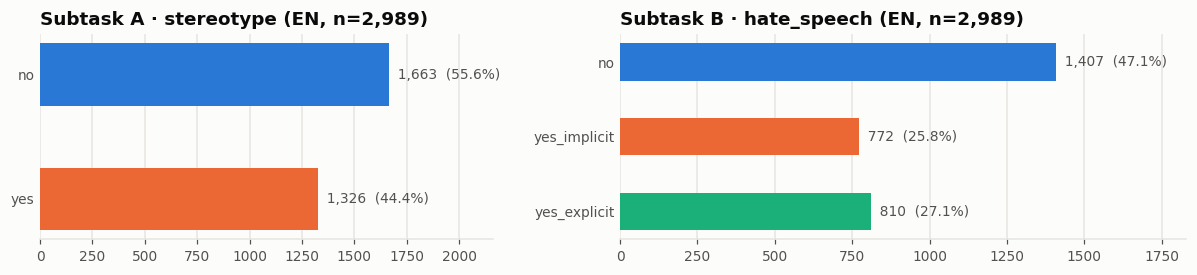

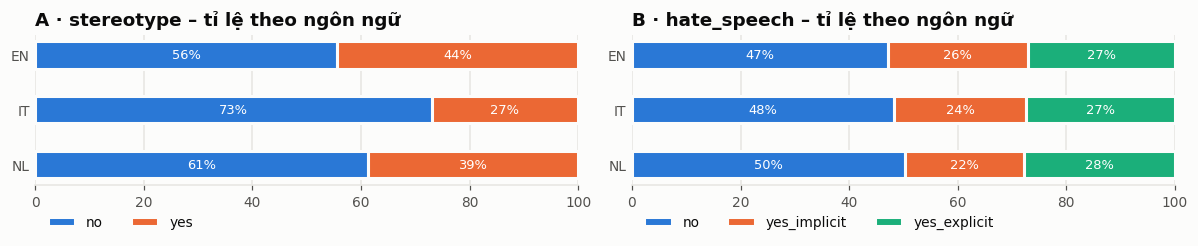

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 2.6), gridspec_kw={"width_ratios": [1, 1.25]})
for ax, col, labels, cmap, title in (
        (axes[0], "stereotype", A_LABELS, COL_A, "Subtask A · stereotype"),
        (axes[1], "hate_speech", B_LABELS, COL_B, "Subtask B · hate_speech")):
    vc = en[col].value_counts().reindex(labels)
    hbar(ax, labels, vc.values, [cmap[l] for l in labels], notes=[f"{p:.1f}%" for p in vc / vc.sum() * 100])
    ax.set_title(f"{title} ({MAIN}, n={len(en):,})")
fig.tight_layout(); savefig(fig, "01_label_distribution_en"); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 2.4))
for ax, col, labels, cmap, title in ((axes[0], "stereotype", A_LABELS, COL_A, "A · stereotype"),
                                     (axes[1], "hate_speech", B_LABELS, COL_B, "B · hate_speech")):
    share = data.groupby("lang")[col].value_counts(normalize=True).unstack().reindex(index=LANGS, columns=labels) * 100
    left = np.zeros(len(LANGS))
    for lab in labels:
        ax.barh(LANGS, share[lab], left=left, height=0.5, color=cmap[lab], edgecolor=SURF, linewidth=2, label=lab, zorder=2)
        for i, (l0, v) in enumerate(zip(left, share[lab])):
            if v >= 12:
                ax.text(l0 + v / 2, i, f"{v:.0f}%", ha="center", va="center", fontsize=8.5, color="white")
        left += share[lab].values
    ax.invert_yaxis(); ax.set_xlim(0, 100); ax.yaxis.grid(False); ax.tick_params(axis="y", length=0)
    ax.set_title(f"{title} – tỉ lệ theo ngôn ngữ")
    ax.legend(ncol=len(labels), loc="upper left", bbox_to_anchor=(0, -0.12))
fig.tight_layout(); savefig(fig, "02_label_share_by_lang"); plt.show()

### 2.1 Mức sàn của metric (để biết model "giỏi" là giỏi so với cái gì)

Tính trên chính tập train EN (chỉ để tham chiếu; baseline chính thức sẽ được tính trên test):
- **Majority**: luôn đoán lớp nhiều nhất.
- **Random đều**: chọn ngẫu nhiên đều các lớp (giống baseline random của ban tổ chức), lấy trung bình 500 lần.
- **Random theo prior**: chọn ngẫu nhiên theo tỉ lệ lớp.

In [11]:
rng = np.random.default_rng(SEED)
rows = []
for col, labels in (("stereotype", A_LABELS), ("hate_speech", B_LABELS)):
    y = en[col].to_numpy()
    prior = en[col].value_counts(normalize=True).reindex(labels).to_numpy()
    maj = en[col].value_counts().idxmax()
    rows.append({
        "task": "A" if col == "stereotype" else "B",
        "majority": f1_score(y, [maj] * len(y), average="macro", labels=labels, zero_division=0),
        "random đều": np.mean([f1_score(y, rng.choice(labels, len(y)), average="macro", labels=labels)
                               for _ in range(500)]),
        "random theo prior": np.mean([f1_score(y, rng.choice(labels, len(y), p=prior), average="macro", labels=labels)
                                      for _ in range(500)]),
    })
floor = pd.DataFrame(rows).set_index("task").round(3)
display(floor)
SUMMARY["metric_floor_en"] = floor.to_dict()

,majority,random đều,random theo prior
task,,,
A,0.357,0.498,0.500
B,0.213,0.327,0.333


→ Với macro-F1, **majority rất tệ** (A ≈ 0,36; B ≈ 0,21) vì F1 của các lớp không được đoán = 0.
Mức "đáng kể" thật sự là random (A ≈ 0,50; B ≈ 0,33). Accuracy **không** được dùng để chọn model.

## 3. Quan hệ giữa Subtask A và B

Chi² = 832.9, p = 1.4e-181, Cramér's V = 0.528, NMI = 0.170


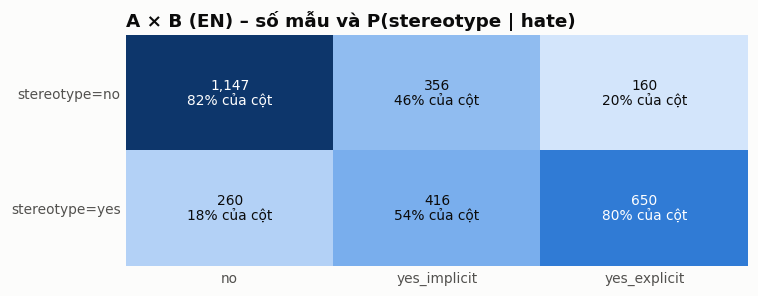

P(hate | stereotype) – % theo hàng:


hate_speech,no,yes_implicit,yes_explicit
stereotype,,,
no,69.0,21.4,9.6
yes,19.6,31.4,49.0


In [12]:
ct = pd.crosstab(en.stereotype, en.hate_speech).reindex(index=A_LABELS, columns=B_LABELS)
row_pct = ct.div(ct.sum(1), axis=0) * 100
col_pct = ct.div(ct.sum(0), axis=1) * 100

chi2, p, dof, _ = chi2_contingency(ct)
cramers_v = np.sqrt(chi2 / (ct.to_numpy().sum() * (min(ct.shape) - 1)))
nmi = normalized_mutual_info_score(en.stereotype, en.hate_speech)
print(f"Chi² = {chi2:.1f}, p = {p:.1e}, Cramér's V = {cramers_v:.3f}, NMI = {nmi:.3f}")
SUMMARY["AB_cramers_v_en"] = round(float(cramers_v), 3)

cells = [[f"{ct.iat[i, j]:,}\n{col_pct.iat[i, j]:.0f}% của cột" for j in range(3)] for i in range(2)]
fig, ax = plt.subplots(figsize=(7, 2.8))
annotated_heatmap(ax, ct.to_numpy(), [f"stereotype={a}" for a in A_LABELS], B_LABELS, cells)
ax.set_title(f"A × B ({MAIN}) – số mẫu và P(stereotype | hate)")
fig.tight_layout(); savefig(fig, "03_AB_crosstab_en"); plt.show()

print("P(hate | stereotype) – % theo hàng:"); display(row_pct.round(1))

In [13]:
# Bảng 6 tổ hợp như handoff yêu cầu + so sánh 3 ngôn ngữ
joint = (data.groupby("lang").joint_AB.value_counts().unstack(0)
         .reindex([f"{a}|{b}" for b in B_LABELS for a in A_LABELS]).reindex(columns=LANGS))
joint_pct = (joint / joint.sum() * 100).round(1)
display(pd.concat({"n": joint, "%": joint_pct}, axis=1))

cond = (data.groupby(["lang", "hate_speech"]).stereotype.apply(lambda s: (s == "yes").mean() * 100)
        .unstack().reindex(index=LANGS, columns=B_LABELS).round(1))
print("P(stereotype = yes | hate_speech), %:"); display(cond)

n                %            
lang                EN    IT   NL    EN    IT    NL
joint_AB                                           
no|no             1147  1096  960  38.4  45.7  42.9
yes|no             260    64  167   8.7   2.7   7.5
no|yes_implicit    356   356  245  11.9  14.8  10.9
yes|yes_implicit   416   225  242  13.9   9.4  10.8
no|yes_explicit    160   300  165   5.4  12.5   7.4
yes|yes_explicit   650   359  459  21.7  15.0  20.5

P(stereotype = yes | hate_speech), %:


hate_speech,no,yes_implicit,yes_explicit
lang,,,
EN,18.5,53.9,80.2
IT,5.5,38.7,54.5
NL,14.8,49.7,73.6


**Diễn giải (EN):**
- A và B **liên quan rõ** nhưng **không phải quan hệ bao hàm**: có comment *stereotype mà không hate* (`yes|no`)
  và *hate mà không stereotype* (`no|yes_implicit`, `no|yes_explicit`). Không thể suy B từ A hay ngược lại bằng luật.
- `yes_explicit` đi kèm stereotype nhiều nhất; `yes_implicit` chia gần đôi → stereotype là tín hiệu hữu ích nhưng không đủ
  để tách implicit khỏi explicit.
- ⇒ Đáng thử **multi-task (một encoder, 2 head A + B)**, hoặc dùng xác suất A làm đặc trưng cho B. Nhãn `target` (C) có thể làm head phụ.
- Ngôn ngữ khác nhau đáng kể (IT gán stereotype ít hơn hẳn) → khi gộp đa ngôn ngữ cần kiểm chứng, đừng mặc định là có lợi.

## 4. Nhãn `target` (Subtask C) – nhìn nhanh

Không nằm trong phạm vi nộp bài, nhưng có giá trị như **nhãn phụ** và để hiểu hate nhắm vào ai.

In [14]:
hate_en = en[en.hate_speech != "no"]
print("Phạm vi target × loại hate (EN), % theo cột:")
display((pd.crosstab(hate_en.target_scope, hate_en.hate_speech, normalize="columns") * 100).round(1))

ids = (data[data.hate_speech != "no"].explode("target_ids")
       .groupby("lang").target_ids.value_counts().unstack(0).reindex(index=IDENTITIES, columns=LANGS).fillna(0).astype(int))
print("Số lần mỗi identity xuất hiện trong mẫu hateful:"); display(ids)
print("Số identity trên một comment (EN):"); display(hate_en.target_ids.map(len).value_counts().sort_index().to_frame("n"))

Phạm vi target × loại hate (EN), % theo cột:


hate_speech,yes_explicit,yes_implicit
target_scope,,
group,73.1,82.1
individual,26.9,17.9


Số lần mỗi identity xuất hiện trong mẫu hateful:


lang,EN,IT,NL
target_ids,,,
l,133,86,55
g,333,252,199
b,59,27,8
t,772,287,550
q,8,7,25
i,14,17,24
a,1,0,1
nb,15,7,118
lgbtqia+,465,704,393


Số identity trên một comment (EN):


,n
target_ids,
1,1409
2,134
3,33
4,6


,EN
số nhãn ghép (joint) khác nhau,42.0
nhãn có < 5 mẫu,22.0
nhãn có < 10 mẫu,29.0
top-5 nhãn phủ (%),82.0


,n,pct
target,,
group_t,510,34.4
group_lgbtqia+,354,23.9
individual_t,233,15.7
group_g,146,9.8
individual_g,55,3.7
"group_l,g",46,3.1
"group_g,lgbtqia+",36,2.4
individual_l,26,1.8
group_l,21,1.4


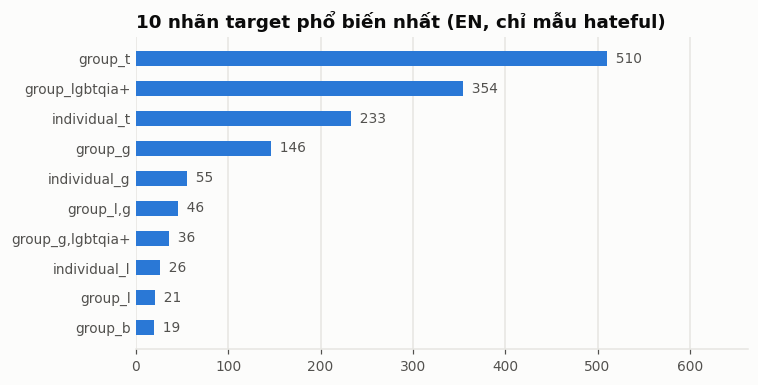

In [15]:
jt = hate_en.target.value_counts()
c_stats = {"số nhãn ghép (joint) khác nhau": len(jt),
           "nhãn có < 5 mẫu": int((jt < 5).sum()),
           "nhãn có < 10 mẫu": int((jt < 10).sum()),
           "top-5 nhãn phủ (%)": round(jt.head(5).sum() / jt.sum() * 100, 1)}
display(pd.Series(c_stats).to_frame(MAIN))
display(jt.head(12).to_frame("n").assign(pct=lambda d: (d.n / d.n.sum() * 100).round(1)))

fig, ax = plt.subplots(figsize=(7, 3.6))
top = jt.head(10)
hbar(ax, top.index.tolist(), top.values, [SERIES[0]] * len(top))
ax.set_title(f"10 nhãn target phổ biến nhất ({MAIN}, chỉ mẫu hateful)")
fig.tight_layout(); savefig(fig, "04_target_top_en"); plt.show()

**Diễn giải:** hate trong EN tập trung vào **người chuyển giới (`t`)** và cộng đồng nói chung (`lgbtqia+`);
`q`, `i`, `a`, `nb` cực hiếm. Macro-F1 trên nhãn ghép của C bị chi phối bởi đuôi dài các nhãn hiếm
→ đây là lý do hợp lý để chỉ làm A+B. Explicit có tỉ lệ nhắm vào **cá nhân** cao hơn implicit
(chửi thẳng một người cụ thể trong video).

## 5. Cấu trúc video & context

Mỗi video có nhiều comment. Câu hỏi: (1) số comment/video phân bố thế nào; (2) **nhãn có phụ thuộc vào video không?**
Nếu có, chia train/validation ngẫu nhiên (các comment cùng video rơi vào cả hai phía) sẽ cho điểm ảo,
trong khi test chính thức lại dùng video mới.

,số video,mean,std,min,25%,50%,75%,max
lang,,,,,,,,
EN,243.0,12.3,7.6,1.0,5.0,12.0,19.0,31.0
IT,187.0,12.8,9.5,1.0,4.0,11.0,20.0,44.0
NL,127.0,17.6,17.4,1.0,3.0,11.0,28.0,67.0


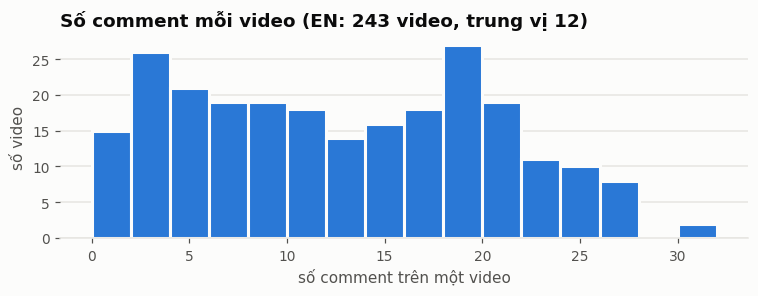

In [16]:
per_video = data.groupby(["lang", "video_id"]).size()
display(per_video.groupby("lang").describe().round(1).rename(columns={"count": "số video"}))

fig, ax = plt.subplots(figsize=(7, 2.8))
pv = per_video.loc[MAIN]
ax.hist(pv, bins=range(0, pv.max() + 3, 2), color=SERIES[0], edgecolor=SURF, linewidth=2, zorder=2)
ax.set_xlabel("số comment trên một video"); ax.set_ylabel("số video"); ax.xaxis.grid(False)
ax.set_title(f"Số comment mỗi video ({MAIN}: {len(pv)} video, trung vị {pv.median():.0f})")
fig.tight_layout(); savefig(fig, "05_comments_per_video_en"); plt.show()

### 5.1 Chủ đề video (theo từ khoá trong title) và phân bố nhãn

In [17]:
TOPICS = [("trans / non-binary", r"\btrans|non-?binary|gender"),
          ("gay / lesbian / bi", r"\bgay|lesbian|bisexual|homosexual|same[- ]sex"),
          ("LGBT chung / pride", r"lgbt|pride|queer|rainbow")]


def topic_of(title):
    t = title.lower()
    for name, pat in TOPICS:
        if re.search(pat, t):
            return name
    return "khác"


en["topic"] = en.yt_title.map(topic_of)
topic_tab = pd.crosstab(en.topic, en.hate_speech).reindex(columns=B_LABELS)
topic_tab.insert(0, "số video", en.groupby("topic").video_id.nunique())
topic_tab["% hateful"] = ((topic_tab.yes_implicit + topic_tab.yes_explicit) / topic_tab[B_LABELS].sum(1) * 100).round(1)
topic_tab["% stereotype"] = (en.groupby("topic").stereotype.apply(lambda s: (s == "yes").mean()) * 100).round(1)
display(topic_tab.sort_values("số video", ascending=False))

hate_speech,số video,no,yes_implicit,yes_explicit,% hateful,% stereotype
topic,,,,,,
gay / lesbian / bi,103,638,259,251,44.4,39.7
trans / non-binary,78,400,345,384,64.6,54.5
LGBT chung / pride,39,252,116,120,48.4,30.7
khác,23,117,52,55,47.8,46.9


### 5.2 Video "dự đoán" được nhãn đến mức nào? (đo rò rỉ tiềm năng)

**Video-prior LOO:** với mỗi comment, đoán nhãn bằng nhãn phổ biến nhất *trong các comment khác của cùng video*.
Đây chính là thông tin mà một model có thể "học vẹt" qua title/description nếu split ngẫu nhiên.

,majority (macro-F1),video-prior LOO (macro-F1)
task,,
A,0.357,0.615
B,0.213,0.485


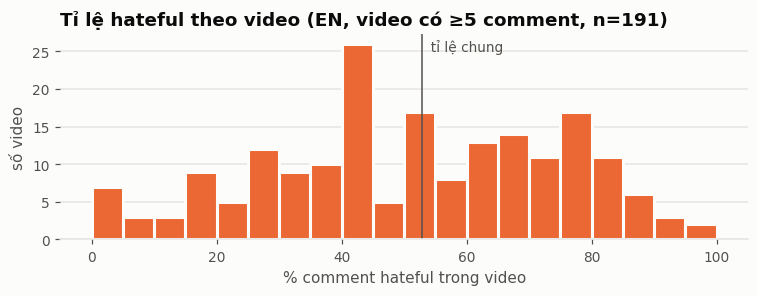

In [18]:
def loo_video_prior(df, col):
    global_major = df[col].value_counts().idxmax()
    pred = pd.Series(index=df.index, dtype=object)
    for _, g in df.groupby("video_id"):
        counts = g[col].value_counts()
        for idx, y in g[col].items():
            c = counts.copy(); c[y] -= 1; c = c[c > 0]
            pred[idx] = c.idxmax() if len(c) else global_major
    return pred


rows = []
for col, labels in (("stereotype", A_LABELS), ("hate_speech", B_LABELS)):
    pred = loo_video_prior(en, col)
    maj = en[col].value_counts().idxmax()
    rows.append({"task": "A" if col == "stereotype" else "B",
                 "majority (macro-F1)": f1_score(en[col], [maj] * len(en), average="macro", labels=labels, zero_division=0),
                 "video-prior LOO (macro-F1)": f1_score(en[col], pred, average="macro", labels=labels, zero_division=0)})
vp = pd.DataFrame(rows).set_index("task").round(3)
display(vp)
SUMMARY["video_prior_loo_en"] = vp.to_dict()

vid_rate = en.groupby("video_id").agg(n=("hate_speech", "size"),
                                      hate_rate=("hate_speech", lambda s: (s != "no").mean()),
                                      stereo_rate=("stereotype", lambda s: (s == "yes").mean()))
vid_rate = vid_rate[vid_rate.n >= 5]
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.hist(vid_rate.hate_rate * 100, bins=np.arange(0, 105, 5), color=SERIES[1], edgecolor=SURF, linewidth=2, zorder=2)
ax.axvline((en.hate_speech != "no").mean() * 100, color=INK2, linewidth=1)
ax.text((en.hate_speech != "no").mean() * 100, ax.get_ylim()[1] * 0.92, "  tỉ lệ chung", color=INK2, fontsize=9)
ax.set_xlabel("% comment hateful trong video"); ax.set_ylabel("số video"); ax.xaxis.grid(False)
ax.set_title(f"Tỉ lệ hateful theo video ({MAIN}, video có ≥5 comment, n={len(vid_rate)})")
fig.tight_layout(); savefig(fig, "06_hate_rate_per_video_en"); plt.show()

**Diễn giải:** tỉ lệ hate dao động mạnh giữa các video và video-prior LOO cao hơn majority rõ rệt
→ **nhãn phụ thuộc video**. Hai hệ quả:
1. Context (title/description) mang thông tin thật — đáng làm thí nghiệm context ablation.
2. Nhưng nếu chia ngẫu nhiên, model sẽ "nhớ video" thay vì hiểu comment → điểm validation bị thổi phồng.
   **Bắt buộc dùng GroupKFold theo `video_id`** (kiểm chứng định lượng ở mục 10).

## 6. Độ dài văn bản

Đếm theo **từ** (tách khoảng trắng) và theo **subword token thật** của các encoder ứng viên cho EN
(`roberta-base`, `microsoft/deberta-v3-base`) và encoder đa ngôn ngữ (`xlm-roberta-base`).

In [19]:
def clean_text(s):
    return re.sub(r"[ \t]+", " ", s.replace("\r\n", "\n").replace("\r", "\n")).strip()


for c in TEXT_COLS:
    data[c + "_clean"] = data[c].map(clean_text)

FIELDS = {
    "title": lambda d: d.yt_title_clean,
    "description": lambda d: d.yt_description_clean,
    "comment": lambda d: d.yt_comment_clean,
    "title + comment": lambda d: d.yt_title_clean + " " + d.yt_comment_clean,
    "title + desc + comment": lambda d: d.yt_title_clean + " " + d.yt_description_clean + " " + d.yt_comment_clean,
}
PCTS = [0.5, 0.9, 0.95, 0.99]


def length_stats(lengths):
    s = pd.Series(lengths)
    return pd.Series({"min": s.min(), "mean": s.mean(), "median": s.median(), "p90": s.quantile(.9),
                      "p95": s.quantile(.95), "p99": s.quantile(.99), "max": s.max()}).round(1)


en = data[data.lang == MAIN].copy()
word_len = pd.DataFrame({name: f(en).str.split().str.len() for name, f in FIELDS.items()})
print(f"Độ dài theo TỪ ({MAIN}):"); display(word_len.apply(length_stats).T)

Độ dài theo TỪ (EN):


,min,mean,median,p90,p95,p99,max
title,3.0,9.6,10.0,14.0,15.0,16.0,17.0
description,7.0,64.8,54.0,127.0,153.0,244.0,343.0
comment,1.0,29.2,17.0,66.2,96.0,179.0,496.0
title + comment,4.0,38.8,27.0,75.2,106.0,187.2,506.0
title + desc + comment,15.0,103.5,88.0,180.2,221.0,330.1,690.0


In [20]:
from transformers import AutoTokenizer
from transformers.utils import logging as hf_logging
from huggingface_hub.utils import logging as hub_logging
hf_logging.set_verbosity_error(); hub_logging.set_verbosity_error()

TOKENIZERS = {}
for name in ["roberta-base", "microsoft/deberta-v3-base", "xlm-roberta-base"]:
    try:
        TOKENIZERS[name] = AutoTokenizer.from_pretrained(name)
    except Exception as e:
        print(f"[bỏ qua] không tải được tokenizer {name}: {type(e).__name__}")


def n_tokens(tok, texts):
    return np.array([len(x) for x in tok(list(texts), add_special_tokens=False)["input_ids"]])


tok_len = {}   # (tokenizer, field) -> array (EN)
for tname, tok in TOKENIZERS.items():
    for fname in ["title", "description", "comment"]:
        tok_len[(tname, fname)] = n_tokens(tok, FIELDS[fname](en))
    tok_len[(tname, "title + comment")] = tok_len[(tname, "title")] + tok_len[(tname, "comment")]
    tok_len[(tname, "title + desc + comment")] = (tok_len[(tname, "title")] + tok_len[(tname, "description")]
                                                 + tok_len[(tname, "comment")])
if tok_len:
    tok_stats = pd.DataFrame({k: length_stats(v) for k, v in tok_len.items()}).T
    tok_stats.index.names = ["tokenizer", "field"]
    print(f"Độ dài theo SUBWORD TOKEN ({MAIN}, chưa tính token đặc biệt):"); display(tok_stats)

Độ dài theo SUBWORD TOKEN (EN, chưa tính token đặc biệt):


min   mean  median    p90    p95    p99     max
tokenizer                 field                                                                   
roberta-base              title                    4.0   13.7    14.0   20.0   22.0   26.0    27.0
                          description             11.0   99.8    82.0  220.0  257.0  445.0   473.0
                          comment                  2.0   37.6    23.0   85.0  119.0  232.4   587.0
                          title + comment          7.0   51.2    37.0   98.0  133.0  243.8   604.0
                          title + desc + comment  20.0  151.1   127.0  278.0  331.6  499.0   879.0
microsoft/deberta-v3-base title                    4.0   12.6    12.0   18.0   19.6   23.0    24.0
                          description             11.0   89.1    75.0  188.0  229.0  380.0   420.0
                          comment                  1.0   36.5    21.0   82.0  116.6  227.0   571.0
                          title + comment          8.0   49.1    35.0   95.2  128.0  238.1   587.0
                          title + desc + comment  20.0  138.2   116.0  249.2  296.8  450.5   836.0
xlm-roberta-base          title                    5.0   15.5    15.0   22.0   23.0   26.0    30.0
                          description             11.0  103.4    88.0  214.0  260.0  426.0   484.0
                          comment                  2.0   40.3    24.0   91.0  130.0  251.0   726.0
                          title + comment         10.0   55.9    40.0  106.0  145.6  267.1   744.0
                          title + desc + comment  28.0  159.2   134.0  285.0  343.6  516.1  1035.0

### 6.1 Bao nhiêu comment bị cắt ở mỗi `max_length`?

So sánh 3 cách đóng gói input (dùng tokenizer `roberta-base`, trừ 4 token đặc biệt cho dạng cặp câu):

| Cách | Mô tả | Rủi ro |
|---|---|---|
| **comment only** | chỉ comment | mất context |
| **naive: title + desc + comment** | nối theo thứ tự, cắt phải | **comment nằm cuối nên bị cắt trước** |
| **pair: (comment, title + desc)** | `tokenizer(comment, context, truncation="only_second")` | chỉ cắt context; comment chỉ bị cắt khi tự nó quá dài |

In [21]:
TOK_MAIN = "roberta-base" if "roberta-base" in TOKENIZERS else next(iter(TOKENIZERS), None)
if TOK_MAIN:
    t_title, t_desc, t_com = (tok_len[(TOK_MAIN, f)] for f in ("title", "description", "comment"))
    rows = []
    for L in [64, 128, 256, 384, 512]:
        rows.append({
            "max_length": L,
            "comment only: % comment bị cắt": (t_com > L - 2).mean() * 100,
            "title+comment (pair): % comment bị cắt": (t_com > L - 4).mean() * 100,
            "title+comment (pair): % title bị cắt": (t_title + t_com > L - 4).mean() * 100,
            "naive t+d+c: % comment bị cắt": (t_title + t_desc + t_com > L - 6).mean() * 100,
            "naive t+d+c: % comment mất HẾT": (t_title + t_desc > L - 6).mean() * 100,
            "pair (c, t+d): % context bị cắt": (t_title + t_desc + t_com > L - 4).mean() * 100,
        })
    trunc = pd.DataFrame(rows).set_index("max_length").round(1)
    display(trunc)
    SUMMARY["truncation_en_roberta"] = trunc.to_dict()

,comment only: % comment bị cắt,title+comment (pair): % comment bị cắt,title+comment (pair): % title bị cắt,naive t+d+c: % comment bị cắt,naive t+d+c: % comment mất HẾT,"pair (c, t+d): % context bị cắt"
max_length,,,,,,
64,15.5,16.1,22.6,89.9,70.8,89.0
128,4.4,4.6,5.9,53.1,29.9,51.7
256,0.9,0.9,0.9,13.9,8.2,13.5
384,0.2,0.2,0.2,3.5,2.1,3.5
512,0.1,0.1,0.1,0.8,0.0,0.7


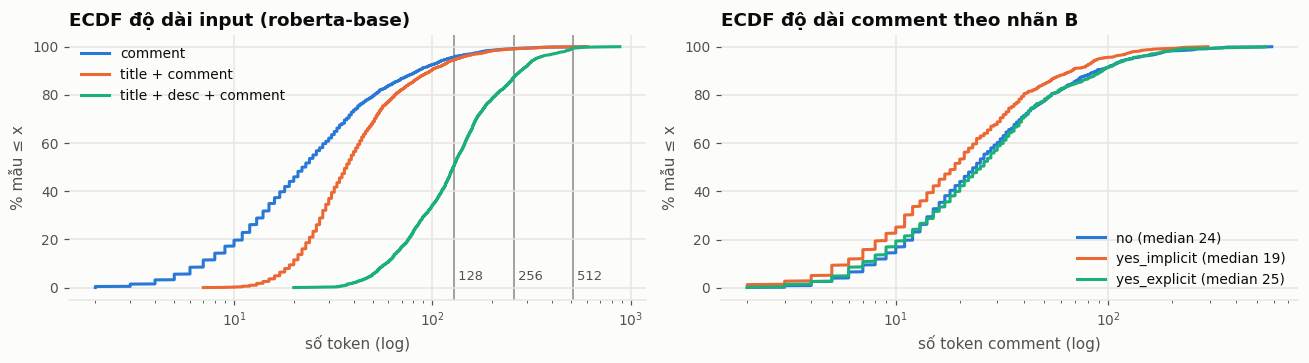

In [22]:
if TOK_MAIN:
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
    ax = axes[0]
    for i, f in enumerate(["comment", "title + comment", "title + desc + comment"]):
        x = np.sort(tok_len[(TOK_MAIN, f)])
        ax.plot(x, np.arange(1, len(x) + 1) / len(x) * 100, color=SERIES[i], label=f)
    for L in (128, 256, 512):
        ax.axvline(L, color=MUTED, linewidth=1, zorder=0)
        ax.text(L, 3, f" {L}", color=INK2, fontsize=8.5)
    ax.set_xscale("log"); ax.set_xlabel("số token (log)"); ax.set_ylabel("% mẫu ≤ x")
    ax.set_title(f"ECDF độ dài input ({TOK_MAIN})"); ax.legend(loc="upper left")

    ax = axes[1]
    for lab in B_LABELS:
        x = np.sort(tok_len[(TOK_MAIN, "comment")][en.hate_speech.to_numpy() == lab])
        ax.plot(x, np.arange(1, len(x) + 1) / len(x) * 100, color=COL_B[lab], label=f"{lab} (median {np.median(x):.0f})")
    ax.set_xscale("log"); ax.set_xlabel("số token comment (log)"); ax.set_ylabel("% mẫu ≤ x")
    ax.set_title("ECDF độ dài comment theo nhãn B"); ax.legend(loc="lower right")
    fig.tight_layout(); savefig(fig, "07_length_ecdf_en"); plt.show()

In [23]:
# Độ dài comment theo nhãn (từ)
en["comment_words"] = en.yt_comment_clean.str.split().str.len()
by_label = pd.concat({
    "A=" + a: length_stats(en.loc[en.stereotype == a, "comment_words"]) for a in A_LABELS} | {
    "B=" + b: length_stats(en.loc[en.hate_speech == b, "comment_words"]) for b in B_LABELS}, axis=1).T
display(by_label)

,min,mean,median,p90,p95,p99,max
A=no,1.0,24.8,14.0,54.0,84.0,171.4,312.0
A=yes,1.0,34.7,20.0,76.5,114.0,184.5,496.0
B=no,1.0,31.4,17.0,71.0,104.4,219.9,496.0
B=yes_implicit,1.0,23.1,14.0,51.0,75.4,135.3,257.0
B=yes_explicit,1.0,31.2,19.0,73.0,100.6,178.1,449.0


**Khuyến nghị độ dài:**
- Comment ngắn (trung vị chỉ vài chục token); `max_length = 128` đã giữ trọn hầu hết comment, `256` gần như giữ hết.
- **Không** ghép naive `title + desc + comment` rồi cắt phải: description dài sẽ đẩy comment ra ngoài cửa sổ.
- Dùng dạng **cặp câu** `tokenizer(comment, title [+ desc], truncation="only_second", max_length=256)`
  → comment luôn được giữ, context bị cắt trước. Nếu dùng description, nên lọc bỏ dòng link/`[URL]`/`[CHANNEL]` và
  chỉ giữ vài câu đầu.
- `yes_implicit` có xu hướng **ngắn hơn** các lớp khác → càng ngắn càng phụ thuộc context.

## 7. Đặc trưng bề mặt theo nhãn

Tỉ lệ (%) comment có một đặc trưng, theo từng lớp. Các nhóm từ khoá được chọn theo những
"trope" thường gặp khi đọc dữ liệu (tôn giáo, sinh học/giới tính, trẻ em, bệnh tâm lý…).
Đây là **phân tích mô tả**, không phải bộ lọc.

In [24]:
FEATURES = {
    "nhắc identity (gay/trans/lgbt…)": r"\b(?:gays?|lesbians?|bi|bisexuals?|trans|transgender\w*|transsexual\w*|trans(?:wom[ae]n|m[ae]n)|queers?|homo\w*|lgbt\w*|non-?binary|intersex|asexual|tranny|trannies|fag\w*|dykes?)\b",
    "đại từ he/she/him/her": r"\b(?:he|him|his|she|her|hers)\b",
    "tôn giáo (god, sin, bible…)": r"\b(?:god|jesus|christ\w*|bible|sin|sins|sinful|sinner\w*|lord|church|allah|satan\w*|abomination|pray\w*|repent\w*|hell)\b",
    "sinh học (biology, dna, xx/xy…)": r"\b(?:biolog\w*|dna|chromosome\w*|xx|xy|genitals?|real (?:wom[ae]n|m[ae]n)|biological\w*)\b",
    "trẻ em (child, kids, groom…)": r"\b(?:child\w*|kids?|minors?|groom\w*|pedo\w*|teen\w*)\b",
    "bệnh tâm lý (mental, sick…)": r"\b(?:mental\w*|sick|ill|illness|delusion\w*|disorder\w*|crazy|insane|confused)\b",
    "phủ định (not, never, n't…)": r"\b(?:not|never|no|nobody|nothing)\b|n't\b",
    "câu hỏi (?)": r"\?",
    "cảm thán (!)": r"!",
    "trích dẫn (\"…\")": r"[\"“”]",
    "emoji": EMOJI_RE,
    "cười (😂, lol, lmao)": r"😂|🤣|\blol\b|\blmao\b|\bhaha\w*",
    "placeholder [CHANNEL]/[USER]": r"\[(?:CHANNEL|USER|URL)\]",
    "VIẾT HOA ≥ 2 từ": r"\b[A-Z]{3,}\b.*\b[A-Z]{3,}\b",
}
feat = pd.DataFrame({k: en.yt_comment_clean.str.contains(p, case=(k.startswith("VIẾT HOA") or k.startswith("placeholder")))
                     for k, p in FEATURES.items()})
rates = pd.concat({**{f"A={a}": feat[en.stereotype.values == a].mean() for a in A_LABELS},
                   **{f"B={b}": feat[en.hate_speech.values == b].mean() for b in B_LABELS}}, axis=1) * 100
rates["tất cả"] = feat.mean() * 100
display(rates.round(1).style.format("{:.1f}").background_gradient(cmap=BLUES, axis=1, subset=rates.columns[:-1]))

,A=no,A=yes,B=no,B=yes_implicit,B=yes_explicit,tất cả
nhắc identity (gay/trans/lgbt…),36.2,38.2,45.3,23.4,35.7,37.1
đại từ he/she/him/her,18.9,22.9,22.4,15.3,22.8,20.7
"tôn giáo (god, sin, bible…)",10.1,15.5,9.2,12.2,18.6,12.5
"sinh học (biology, dna, xx/xy…)",1.0,5.6,1.7,3.4,4.9,3.0
"trẻ em (child, kids, groom…)",4.1,11.2,5.3,6.6,11.1,7.2
"bệnh tâm lý (mental, sick…)",2.3,7.7,2.7,3.4,9.5,4.7
"phủ định (not, never, n't…)",31.9,48.0,38.7,32.8,45.4,39.0
câu hỏi (?),15.2,17.6,17.6,16.5,13.8,16.3
cảm thán (!),16.7,14.6,15.8,15.5,16.0,15.8
"trích dẫn (""…"")",6.6,10.8,8.2,8.4,9.0,8.5


In [25]:
hateful = en.hate_speech != "no"
no_id = ~feat["nhắc identity (gay/trans/lgbt…)"].values
share_no_id = pd.Series({b: no_id[en.hate_speech.values == b].mean() * 100 for b in B_LABELS}).round(1)
print("% comment KHÔNG nhắc trực tiếp từ chỉ identity, theo nhãn B:"); display(share_no_id.to_frame("%"))
SUMMARY["pct_hateful_without_identity_term_en"] = round(float(no_id[hateful.values].mean() * 100), 1)

print("Ví dụ comment hateful không nhắc identity (phải dựa vào context/đại từ):")
display(en.loc[hateful.values & no_id, ["yt_title", "yt_comment", "hate_speech", "target"]]
        .sample(10, random_state=SEED))

% comment KHÔNG nhắc trực tiếp từ chỉ identity, theo nhãn B:


,%
no,54.7
yes_implicit,76.6
yes_explicit,64.3


Ví dụ comment hateful không nhắc identity (phải dựa vào context/đại từ):


,yt_title,yt_comment,hate_speech,target
1115,US funding cuts are closing clinics in South Africa and putting transgender health care at risk,"And this is a bad thing, South Africa can't find their own weirdos ???",yes_implicit,group_t
1365,Vatican hosts first Catholic LGBTQ pilgrimage,"Christianity is dying, becoming Gayanity 😂✝️🏳️‍🌈",yes_implicit,group_lgbtqia+
130,Vatican hosts first Catholic LGBTQ pilgrimage,Abomination...sacrilege...\r\n.🙄🫥🫣😑,yes_explicit,group_lgbtqia+
1757,Owen Jones meets Munroe Bergdorf | ‘It's like people have free rein to harass the trans community’,That human is a demon ina dress,yes_explicit,individual_t
1829,LIVE: Supreme Court hears arguments on state laws barring transgender athletes from school sports,ITS SIMPLE EVERY CELL IN A MANS BODY IS DIFFERENT THEN THE FEMALE CELL WITH THE EXCEPTION OF REPRODUCTIVE ORGANS,yes_implicit,group_t
1554,Mother of transgender teen weighs in ahead of Supreme Court hearing,Nobody wants to participate in your delusions!!!! Stop imposing your beliefs on others.,yes_implicit,group_t
380,Gay priest: Roman Catholic Church 'violently homophobic' - [CHANNEL],"Jas 4:4\r\nYe adulterers and adulteresses, know ye not that the friendship of the world is enmity with God? whosoever therefore will be ...",yes_implicit,group_lgbtqia+
232,Transgender Navy vet challenges Scott Jennings on military ban,If flat feet can disqualify you from the military so should having both a penis and boobs,yes_implicit,group_t
524,Supreme Court lets Trump block transgender people from choosing passport sex markers,"Excellent. Its factual information, not pretend",yes_explicit,group_t
2558,Transgender women go to lunch with Pope Francis,Hellfire be upon Francis.,yes_implicit,group_t


**Diễn giải (EN):**
- **~77% comment `yes_implicit` không nhắc tới nhóm bị nhắm** (explicit ~64%, thậm chí còn ít hơn comment `no` ~55%).
  Đối tượng chỉ hiểu được qua video: đại từ *he/she*, *"That's a man"*, *"Based Poland"*, *"I stand with Hungary"*,
  *"Thank you Nancy"* → bằng chứng mạnh để thử thêm **title** vào input.
- Các trope **tôn giáo, trẻ em, bệnh tâm lý, "sinh học"** cao rõ ở `stereotype = yes` và `yes_explicit`
  → bag-of-words bắt được phần này; phần khó là các comment **không có từ khoá**.
- Phủ định nhiều hơn hẳn ở stereotype/hate (*"a man is **not** a woman"*, *"it **isn't** care"*) → không được bỏ stopword phủ định.
- `[CHANNEL]` hay gặp ở implicit hơn: comment công kích kênh tin tức đưa tin LGBT.
- Emoji nhiều hơn ở lớp `no` (🌈 ❤️ ủng hộ), còn emoji cười 😂 **không** phân biệt lớp → đừng coi 😂 là tín hiệu châm biếm.

## 8. Từ vựng phân biệt giữa các lớp

Dùng **weighted log-odds ratio với informative Dirichlet prior** (Monroe, Colaresi & Quinn, 2008):
ổn định hơn so sánh tần suất thô vì phạt các từ hiếm. Token = unigram + bigram, lowercase. `z > 0` nghiêng về lớp thứ nhất.

Hai biện pháp chống "từ giả": (1) mỗi term chỉ đếm **một lần trên một comment**, (2) chỉ giữ term xuất hiện ở **≥ 3 video**.
Không có hai biện pháp này, một comment dài lặp cụm *"Ford Mustang"* hàng chục lần đã chiếm top từ đặc trưng của implicit
— chính là kiểu tín hiệu gắn với một video mà model cũng có thể học vẹt.

In [26]:
TOKEN_RE = re.compile(r"[a-z]+(?:'[a-z]+)?|" + EMOJI_RE)


def tokenize(s):
    toks = TOKEN_RE.findall(s.lower())
    return toks + [f"{a} {b}" for a, b in zip(toks, toks[1:])]


MIN_VIDEOS = 3
en_tokens = en.yt_comment_clean.map(lambda s: set(tokenize(s)))     # đếm theo comment, không theo số lần lặp
prior_counts = Counter(t for ts in en_tokens for t in ts)
term_videos = {}
for ts, v in zip(en_tokens, en.video_id):
    for t in ts:
        term_videos.setdefault(t, set()).add(v)


def log_odds(mask_a, mask_b, min_count=8, top=15):
    ca = Counter(t for ts in en_tokens[mask_a] for t in ts)
    cb = Counter(t for ts in en_tokens[mask_b] for t in ts)
    na, nb, a0 = sum(ca.values()), sum(cb.values()), sum(prior_counts.values())
    rows = []
    for w, aw in prior_counts.items():
        ya, yb = ca.get(w, 0), cb.get(w, 0)
        if ya + yb < min_count or len(term_videos[w]) < MIN_VIDEOS:
            continue
        d = (np.log((ya + aw) / (na + a0 - ya - aw)) - np.log((yb + aw) / (nb + a0 - yb - aw)))
        rows.append((w, d / np.sqrt(1 / (ya + aw) + 1 / (yb + aw)), ya, yb))
    r = pd.DataFrame(rows, columns=["term", "z", "n_a", "n_b"]).sort_values("z")
    return r.tail(top)[::-1].reset_index(drop=True), r.head(top).reset_index(drop=True)


CONTRASTS = [("A: stereotype yes vs no", en.stereotype == "yes", en.stereotype == "no"),
             ("B: explicit vs no", en.hate_speech == "yes_explicit", en.hate_speech == "no"),
             ("B: implicit vs no", en.hate_speech == "yes_implicit", en.hate_speech == "no"),
             ("B: implicit vs explicit", en.hate_speech == "yes_implicit", en.hate_speech == "yes_explicit")]
lo_results = {}
for name, ma, mb in CONTRASTS:
    pos, neg = log_odds(ma.values, mb.values)
    lo_results[name] = (pos, neg)
    a, b = name.split(": ")[1].split(" vs ")
    fmt = lambda df: df.term + "  (" + df.z.round(1).astype(str) + ")"
    display(Markdown(f"**{name}**"))
    display(pd.DataFrame({f"→ {a}": fmt(pos), f"→ {b}": fmt(neg)}))

**A: stereotype yes vs no**

,→ stereotype yes,→ no
0,woman (3.4),love (-3.6)
1,a woman (3.3),i (-3.4)
2,women (3.3),thank you (-3.2)
3,sports (3.2),🌈 (-3.1)
4,men (3.2),❤ (-3.1)
5,girls (3.1),🏳 (-3.0)
6,male (2.7),🏳 🌈 (-2.9)
7,a man (2.6),thank (-2.8)
8,sin (2.6),comments (-2.6)
9,female (2.6),much (-2.6)


**B: explicit vs no**

,→ explicit,→ no
0,a man (3.0),love (-3.0)
1,woman (2.9),me (-2.6)
2,a woman (2.9),comments (-2.6)
3,man (2.7),i'm (-2.5)
4,sin (2.5),i (-2.4)
5,disgusting (2.4),people (-2.4)
6,abomination (2.4),bisexual (-2.0)
7,repent (2.3),gay (-2.0)
8,girls (2.3),thank you (-2.0)
9,god (2.3),lot (-2.0)


**B: implicit vs no**

,→ implicit,→ no
0,hungary (2.6),love (-2.6)
1,sports (2.4),comments (-2.3)
2,channel (2.3),gay (-2.1)
3,the channel (1.9),lgbt (-1.9)
4,girls (1.9),i'm (-1.8)
5,woke (1.9),me (-1.7)
6,nonsense (1.7),beautiful (-1.7)
7,money (1.6),people (-1.6)
8,common sense (1.6),homophobic (-1.6)
9,goes (1.6),brave (-1.6)


**B: implicit vs explicit**

,→ implicit,→ explicit
0,channel (1.8),disgusting (-2.0)
1,the channel (1.7),abomination (-2.0)
2,the (1.5),not a (-1.6)
3,of course (1.5),an abomination (-1.5)
4,hungary (1.5),a woman (-1.5)
5,course (1.5),no such (-1.5)
6,rules (1.5),such thing (-1.5)
7,i (1.4),born (-1.5)
8,to (1.3),woman (-1.5)
9,goes (1.3),perverted (-1.5)


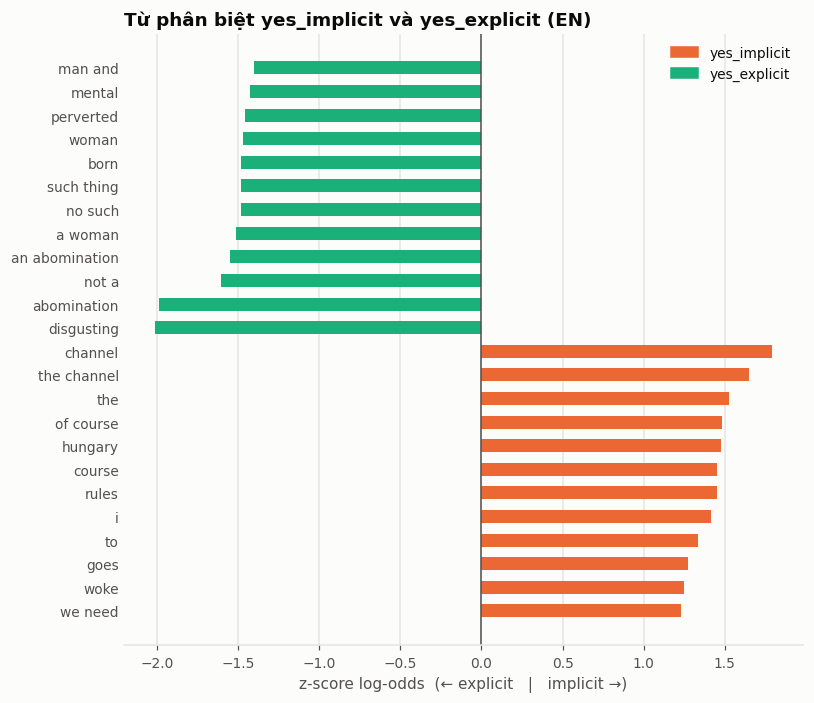

In [27]:
pos, neg = lo_results["B: implicit vs explicit"]
k = 12
terms = list(pos.term[:k][::-1]) + list(neg.term[:k])
zs = list(pos.z[:k][::-1]) + list(neg.z[:k])
fig, ax = plt.subplots(figsize=(7.5, 6.5))
y = np.arange(len(terms))
ax.barh(y, zs, height=0.55, color=[COL_B["yes_implicit"] if z > 0 else COL_B["yes_explicit"] for z in zs], zorder=2)
ax.set_yticks(y, terms); ax.yaxis.grid(False); ax.tick_params(axis="y", length=0)
ax.axvline(0, color=INK2, linewidth=1)
ax.set_xlabel("z-score log-odds  (← explicit   |   implicit →)")
ax.set_title("Từ phân biệt yes_implicit và yes_explicit (EN)")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=COL_B["yes_implicit"], label="yes_implicit"),
                   Patch(color=COL_B["yes_explicit"], label="yes_explicit")], loc="upper right")
fig.tight_layout(); savefig(fig, "08_logodds_implicit_vs_explicit_en"); plt.show()

**Diễn giải (EN):**
- **Stereotype = yes**: xoay quanh giới tính sinh học & thể thao (*woman, a man, male/female, body, sports, compete*)
  — tranh luận người chuyển giới trong thể thao — cùng tôn giáo (*sin*). Lớp `no`: *love, thank you,* 🌈 ❤️.
- **Explicit**: ghê tởm / phi nhân hoá / phủ nhận danh tính (*disgusting, abomination, perverted, mental, "not a woman",
  "no such thing as"*) — bag-of-words bắt khá tốt.
- **Implicit**: lập luận "nghe có vẻ lịch sự" (*common sense, nonsense, woke, rules, participate, compete*), ủng hộ quốc gia/chính trị gia
  có luật chống LGBT (*hungary*), công kích kênh tin tức (*the channel*). Để ý *hungary* lại nằm ở phía `stereotype = no`
  → hate mà không cần stereotype.
- **Implicit vs explicit**: z-score lớn nhất chỉ ≈ 2 (các cặp khác lên tới 3–3,6) → **hai lớp này gần như không tách được bằng từ vựng**.
  Đây là chỗ TF-IDF sẽ yếu nhất; kỳ vọng transformer + context giúp nhiều nhất ở đây.

## 9. Ví dụ định tính: comment rất ngắn, các ô của bảng A × B

Mục đích: hiểu "gu" chú thích trước khi train. Đọc kỹ các ô `yes|no` (stereotype nhưng không hate) và
`no|yes_implicit` (hate nhưng không stereotype) — đây là các trường hợp dễ bị model nhầm.

In [28]:
short = en[en.comment_words <= 3]
print(f"Comment ≤ 3 từ: {len(short)} mẫu ({len(short) / len(en) * 100:.1f}%)")
display(pd.concat({"≤3 từ": short.hate_speech.value_counts(normalize=True),
                   "tất cả": en.hate_speech.value_counts(normalize=True)}, axis=1).reindex(B_LABELS).mul(100).round(1))
display(short[["yt_title", "yt_comment", "stereotype", "hate_speech"]].sample(12, random_state=1))

Comment ≤ 3 từ: 118 mẫu (3.9%)


,≤3 từ,tất cả
hate_speech,,
no,36.4,47.1
yes_implicit,39.0,25.8
yes_explicit,24.6,27.1


,yt_title,yt_comment,stereotype,hate_speech
2421,"The queer revolution in the Middle East: 'One good song can do more than 5,000 protests'",Truly Brave people.,no,no
1439,GOP Rep. attends gay son's wedding after opposing protections for same-sex marriage,hypocrite,no,no
1555,Joel Osteen: scripture clear on gay marriage,Great job Joel,no,yes_implicit
2947,Duck Dynasty' star: Homosexuality wrong,He's right,yes,yes_implicit
1889,Old Lesbians: reclaiming old age and queerness through storytelling,Brilliant!,no,no
1343,Colombians celebrate Pride in defiance against LGBTQ violence,Let's read bible.,no,yes_implicit
1052,GOP Congresswoman uses anti-trans slur in House hearing,Nancy Mace rules,no,yes_implicit
2112,GOP Congresswoman uses anti-trans slur in House hearing,Thank you Nancy,no,yes_implicit
1349,Tricked into conversion therapy in Russia for being trans | [CHANNEL],Ridiculous Western Propaganda,no,yes_implicit
2440,Ben Carson apologizes for comments on gay people,Who cares🤷‍♂️,no,yes_implicit


In [29]:
def show_cell(a, b, n=4):
    d = en[(en.stereotype == a) & (en.hate_speech == b)]
    display(Markdown(f"**stereotype = `{a}` · hate_speech = `{b}`** — {len(d)} mẫu"))
    out = d.sample(min(n, len(d)), random_state=SEED)[["yt_title", "yt_comment", "target"]].copy()
    out["yt_comment"] = out.yt_comment.str.slice(0, 300)
    display(out)


for b in B_LABELS:
    for a in A_LABELS:
        show_cell(a, b)

**stereotype = `no` · hate_speech = `no`** — 1147 mẫu

,yt_title,yt_comment,target
835,Supreme Court lets Trump block transgender people from choosing passport sex markers,There’s nothing supreme about this court they are a disgrace.,none
2918,Transgender women go to lunch with Pope Francis,The soul has no gender. It is those who love the world who would deny the least of us and condemn those who are not like themselves.,none
2344,The HIV success story that’s failing gay men - [CHANNEL],"This is so extremely sad, I hope that they will be able to get safe soon.",none
1201,Trans Master Sgt. grieves loss of military career,Thank you for your service. Shame on this administration,none


**stereotype = `yes` · hate_speech = `no`** — 260 mẫu

,yt_title,yt_comment,target
393,I transitioned and lost my male privilege' - [CHANNEL],if changed from women to men.... i doubt she would say it because it doesn't benefit her.and also this is garbage acting,none
1714,Davis: 'Bisexuality does exist',"""Bi people dont exist""\r\n\r\nMr. Stark i dont feel so good",none
2298,‘Clearly saying that because I’m gay’: Garcia responds to Comer ‘queen’ dig,My my husband is a drama queen and he’s straight but the drama he spits out drive you crazy he nags like a woman,none
1821,Model comes out as intersex,"Since she is intersex, why is she wearing women's clothing? Aren't there intersex clothes?",none


**stereotype = `no` · hate_speech = `yes_implicit`** — 356 mẫu

...

,yt_title,yt_comment,target
992,"Russia: gay relationships like drug or alcohol abuse, says sports minister",US government! Stop discriminating straight people and their kids!,group_lgbtqia+
1827,Vatican hosts first Catholic LGBTQ pilgrimage,This is sad and rather unfortunate. Let us not condemn but rather pray for these misguided people.,group_lgbtqia+
2914,Boy George: 'Come out' if it makes you happy,Who cares. I came to [CHANNEL] channel looking for NEWS. Silly me! This is garbage.,group_lgbtqia+
538,Trans influencer receives wrong gender marker on her passport,It's your sex on the passport NOT your gender! I thought you were transGENDER?,individual_t


**stereotype = `no` · hate_speech = `yes_explicit`** — 160 mẫu

,yt_title,yt_comment,target
2104,US funding cuts are closing clinics in South Africa and putting transgender health care at risk,"Hang on, so they actually nailed it when they made accusations of USAID funding trans clinics? 😮😮😮\r\n\r\nWay to go, **** them",group_t
2198,Vatican hosts first Catholic LGBTQ pilgrimage,Banned This group. Chase them to Mars Planet,group_lgbtqia+
2670,Harry Potter star says 'transgender women are women',"They are women in terms of gender but they will always be male in terms of sex. I don't mind if a man is socially accepted as a woman, b...",group_t
1031,[CHANNEL]’s Anderson Cooper grills Florida AG Bondi over gay rights record (2016),LGBT repent and be saved,group_lgbtqia+


**stereotype = `yes` · hate_speech = `yes_explicit`** — 650 mẫu

,yt_title,yt_comment,target
2927,"Ben Carson: Being gay is a choice, look at inmates",Ronnie and Jonnie smelled the pooh...chose a better life. \r\nIt was always a choice.,group_g
1058,Fighting Trump’s transgender military ban,That's just a bearded women,individual_t
1892,Should trans athletes compete in female categories? - [CHANNEL] Newsnight,"If you are XY , have balls and dixk, we don't give a fxcking sh!t how you identify yourself or how your emotion might be fxcking hurt. ...",group_t
1479,Are Americans scared to talk about transgender issues? Analysts discuss,"Yall can do these talks as much as you want, the whole Trans thing is disgusting and off putting. That's my opinion and it's not going t...",group_t


In [30]:
# Xuất file để cả nhóm đọc tay (15 mẫu mỗi tổ hợp A×B), có sẵn cột ghi chú.
reading = (en.groupby("joint_AB", group_keys=False)
           .apply(lambda g: g.sample(min(15, len(g)), random_state=SEED))
           [["StereoQueerEval_id", "video_id", "yt_title", "yt_comment", "stereotype", "hate_speech", "target"]]
           .assign(can_context="", ghi_chu=""))
reading_path = OUT_DIR / "en_reading_sample.csv"
reading.to_csv(reading_path, index=False, encoding="utf-8-sig")
print("Đã lưu:", reading_path, reading.shape)

Đã lưu: C:\Users\Public\Documents\NĂM 3\NLP\SemEval2027_Task8\outputs\eda\en_reading_sample.csv (90, 9)


## 10. So sánh nhanh EN / IT / NL

Câu hỏi cho Stage 5: *thêm dữ liệu IT/NL có giúp EN không?* Trước hết xem các ngôn ngữ có "giống nhau" về phân bố không.

In [31]:
XLMR = TOKENIZERS.get("xlm-roberta-base")
rows = []
for lang, d in data.groupby("lang"):
    h = d[d.hate_speech != "no"]
    id_counts = h.explode("target_ids").target_ids.value_counts(normalize=True) * 100
    rows.append({
        "lang": lang, "n": len(d), "số video": d.video_id.nunique(),
        "comment/video (median)": d.groupby("video_id").size().median(),
        "% stereotype": (d.stereotype == "yes").mean() * 100,
        "% no": (d.hate_speech == "no").mean() * 100,
        "% implicit": (d.hate_speech == "yes_implicit").mean() * 100,
        "% explicit": (d.hate_speech == "yes_explicit").mean() * 100,
        "P(stereo|implicit)": (d[d.hate_speech == "yes_implicit"].stereotype == "yes").mean() * 100,
        "P(stereo|explicit)": (d[d.hate_speech == "yes_explicit"].stereotype == "yes").mean() * 100,
        "P(stereo|no)": (d[d.hate_speech == "no"].stereotype == "yes").mean() * 100,
        "% target cá nhân": (h.target_scope == "individual").mean() * 100,
        "% identity = t": id_counts.get("t", 0), "% identity = lgbtqia+": id_counts.get("lgbtqia+", 0),
        "comment tokens median (XLM-R)": np.median(n_tokens(XLMR, d.yt_comment_clean)) if XLMR else np.nan,
        "desc tokens median (XLM-R)": np.median(n_tokens(XLMR, d.yt_description_clean)) if XLMR else np.nan,
    })
cross = pd.DataFrame(rows).set_index("lang").round(1)
display(cross.T)
SUMMARY["cross_lingual"] = cross.T.to_dict()

lang,EN,IT,NL
n,2989.0,2400.0,2238.0
số video,243.0,187.0,127.0
comment/video (median),12.0,11.0,11.0
% stereotype,44.4,27.0,38.8
% no,47.1,48.3,50.4
% implicit,25.8,24.2,21.8
% explicit,27.1,27.5,27.9
P(stereo|implicit),53.9,38.7,49.7
P(stereo|explicit),80.2,54.5,73.6
P(stereo|no),18.5,5.5,14.8


**Diễn giải:** tỉ lệ hate tương đối giống nhau giữa 3 ngôn ngữ, nhưng **khái niệm stereotype được gán khác nhau**
(IT thấp hơn hẳn, đặc biệt khi hate = no) và **đối tượng bị nhắm khác nhau** (EN nghiêng về `t`, IT về `lgbtqia+`).
⇒ Gộp IT/NL vào train EN có thể giúp B nhưng có thể làm lệch A. Đây là giả thuyết cần đo ở Stage 5
(so sánh *EN-only* vs *EN+IT+NL* trên **cùng folds EN**), không nên giả định trước.

## 11. Tạo validation split theo video (dùng chung cho mọi notebook sau)

Thiết kế:
- `StratifiedGroupKFold(n_splits=5)`: **group = `video_id`** (giống test chính thức: video mới), **stratify = tổ hợp A×B** (6 lớp).
- Thử 50 seed, chọn seed cho phân bố nhãn giữa các fold đều nhất (độ lệch tối đa nhỏ nhất) — vì video có số comment khác nhau
  nên một seed bất kỳ có thể cho fold lệch.
- Mỗi fold ≈ 600 mẫu EN — xấp xỉ cỡ test EN (743). Dùng **fold 0 làm dev nhanh**, **5-fold CV** cho kết quả báo cáo.
- Làm cho cả IT và NL để dùng khi thử đa ngôn ngữ.

In [32]:
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold

N_SPLITS = 5


def make_folds(d, seed):
    fold = np.full(len(d), -1)
    sgkf = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=seed)
    for k, (_, va) in enumerate(sgkf.split(d, d.joint_AB, groups=d.video_id)):
        fold[va] = k
    return fold


def fold_imbalance(d, fold):
    glob = d.joint_AB.value_counts(normalize=True)
    share = pd.crosstab(fold, d.joint_AB, normalize="index")
    size = pd.Series(fold).value_counts(normalize=True)
    return float(max((share - glob).abs().to_numpy().max(), (size - 1 / N_SPLITS).abs().max()))


fold_frames, chosen = [], {}
for lang, d in data.groupby("lang"):
    d = d.reset_index(drop=True)
    scores = {s: fold_imbalance(d, make_folds(d, s)) for s in range(50)}
    best = min(scores, key=scores.get)
    d["fold"] = make_folds(d, best)
    chosen[lang] = {"seed": best, "max_deviation": round(scores[best], 4)}
    # Không video nào nằm ở 2 fold
    assert d.groupby("video_id").fold.nunique().max() == 1
    fold_frames.append(d)
folds = pd.concat(fold_frames, ignore_index=True)
display(pd.DataFrame(chosen).T)

en_f = folds[folds.lang == MAIN]
rep = pd.crosstab(en_f.fold, en_f.hate_speech).reindex(columns=B_LABELS)
rep.insert(0, "n", en_f.groupby("fold").size()); rep.insert(1, "số video", en_f.groupby("fold").video_id.nunique())
rep["% stereotype"] = (en_f.groupby("fold").stereotype.apply(lambda s: (s == "yes").mean()) * 100).round(1)
for b in B_LABELS:
    rep[f"% {b}"] = (rep[b] / rep.n * 100).round(1)
print(f"Kiểm tra các fold ({MAIN}):"); display(rep)

,seed,max_deviation
EN,48.0,0.0011
IT,37.0,0.0017
NL,5.0,0.0100


Kiểm tra các fold (EN):


hate_speech,n,số video,no,yes_implicit,yes_explicit,% stereotype,% no,% yes_implicit,% yes_explicit
fold,,,,,,,,,
0,599,49,282,155,162,44.4,47.1,25.9,27.0
1,599,51,282,155,162,44.2,47.1,25.9,27.0
2,597,52,281,154,162,44.4,47.1,25.8,27.1
3,597,50,281,154,162,44.4,47.1,25.8,27.1
4,597,41,281,154,162,44.4,47.1,25.8,27.1


In [33]:
cols_out = ["StereoQueerEval_id", "lang", "video_id", "fold", "stereotype", "hate_speech", "target"]
for lang in LANGS:
    folds.loc[folds.lang == lang, cols_out].to_csv(SPLIT_DIR / f"folds_{lang.lower()}.csv", index=False)
folds[cols_out].to_csv(SPLIT_DIR / "folds_all.csv", index=False)
print("Đã lưu:", sorted(p.name for p in SPLIT_DIR.glob("*.csv")))
print("Cách dùng:  folds = pd.read_csv('data/splits/folds_en.csv'); df = df.merge(folds[['StereoQueerEval_id','fold']])")

Đã lưu: ['folds_all.csv', 'folds_en.csv', 'folds_it.csv', 'folds_nl.csv']
Cách dùng:  folds = pd.read_csv('data/splits/folds_en.csv'); df = df.merge(folds[['StereoQueerEval_id','fold']])


### 11.1 Kiểm chứng: split ngẫu nhiên có làm điểm ảo không?

**Sanity check, không phải baseline chính thức** (baseline làm ở Notebook 02). Cùng một model TF-IDF + Logistic Regression,
đánh giá 5-fold theo 2 cách: **ngẫu nhiên** (StratifiedKFold) và **theo video** (folds vừa tạo), với 3 kiểu input.
Đặc biệt chú ý input **chỉ có title + description** (không thấy comment!): nếu split ngẫu nhiên cho điểm cao thì đó là rò rỉ.

In [34]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

en_f = en_f.copy()
INPUTS = {
    "comment only": en_f.yt_comment_clean,
    "title + desc only (KHÔNG có comment)": en_f.yt_title_clean + " \n " + en_f.yt_description_clean,
    "title + desc + comment": en_f.yt_title_clean + " \n " + en_f.yt_description_clean + " \n " + en_f.yt_comment_clean,
}
random_folds = np.full(len(en_f), -1)
for k, (_, va) in enumerate(StratifiedKFold(N_SPLITS, shuffle=True, random_state=SEED).split(en_f, en_f.joint_AB)):
    random_folds[va] = k
SPLITS = {"random split": random_folds, "group-by-video": en_f.fold.to_numpy()}


def cv_macro_f1(texts, y, fold, labels):
    scores = []
    for k in range(N_SPLITS):
        tr, va = fold != k, fold == k
        model = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True),
                              LogisticRegression(max_iter=2000, class_weight="balanced", C=2.0))
        model.fit(texts[tr], y[tr])
        scores.append(f1_score(y[va], model.predict(texts[va]), average="macro", labels=labels))
    return np.mean(scores), np.std(scores)


rows = []
for task, col, labels in (("A", "stereotype", A_LABELS), ("B", "hate_speech", B_LABELS)):
    y = en_f[col].to_numpy()
    for iname, texts in INPUTS.items():
        for sname, fold in SPLITS.items():
            m, s = cv_macro_f1(texts.to_numpy(), y, fold, labels)
            rows.append({"task": task, "input": iname, "split": sname, "macro-F1": f"{m:.3f} ± {s:.3f}", "_m": m})
leak = pd.DataFrame(rows)
leak_tab = leak.pivot_table(index=["task", "input"], columns="split", values="_m", aggfunc="first")
leak_tab["chênh lệch (random − group)"] = leak_tab["random split"] - leak_tab["group-by-video"]
display(leak_tab.round(3))
SUMMARY["leakage_check_tfidf_lr"] = {f"{t}|{i}": r.round(3).to_dict() for (t, i), r in leak_tab.iterrows()}

split                                      group-by-video  random split  chênh lệch (random − group)
task input                                                                                          
A    comment only                                   0.686         0.701                        0.015
     title + desc + comment                         0.639         0.639                        0.001
     title + desc only (KHÔNG có comment)           0.530         0.587                        0.057
B    comment only                                   0.510         0.521                        0.012
     title + desc + comment                         0.455         0.480                        0.025
     title + desc only (KHÔNG có comment)           0.397         0.440                        0.043

**Đọc bảng (TF-IDF + LR):**
- **Rò rỉ có thật nhưng vừa phải với model bag-of-words:** split ngẫu nhiên thổi phồng điểm ở mọi cấu hình, mạnh nhất ở input
  *chỉ có title + desc* (+0,04–0,06 macro-F1) — lúc đó model đang nhận diện video chứ không đọc comment.
  Transformer nhớ tốt hơn nhiều nên mức thổi phồng có thể còn lớn hơn → **chỉ báo cáo trên folds theo video**
  (`data/splits/folds_en.csv`).
- Ngay cả trên folds theo video, *chỉ title + desc* vẫn hơn random (A ≈ 0,53 vs 0,50; B ≈ 0,40 vs 0,33):
  context mang tín hiệu tổng quát hoá được (ví dụ video về chuyển giới hút nhiều hate hơn, xem mục 5.1).
- **Ghép naive title + desc + comment vào một túi từ làm GIẢM điểm** so với comment only (A −0,05; B −0,06):
  description dài lấn át comment. ⇒ Context ablation ở các notebook sau phải đưa context vào **có kiểm soát**
  (đặc trưng tách riêng, hoặc cặp câu cho transformer), không ghép thẳng.

## 12. Lưu tóm tắt

In [35]:
SUMMARY.update({
    "n_train": data.groupby("lang").size().to_dict(),
    "n_videos": data.groupby("lang").video_id.nunique().to_dict(),
    "label_dist_A_pct": (data.groupby("lang").stereotype.value_counts(normalize=True) * 100).round(1).unstack().to_dict("index"),
    "label_dist_B_pct": (data.groupby("lang").hate_speech.value_counts(normalize=True) * 100).round(1).unstack().to_dict("index"),
    "folds": chosen,
})
with open(OUT_DIR / "eda_summary.json", "w", encoding="utf-8") as f:
    json.dump(SUMMARY, f, ensure_ascii=False, indent=2, default=str)
print("Đã lưu:", OUT_DIR / "eda_summary.json")
print("Hình:", sorted(p.name for p in FIG_DIR.glob("*.png")))

Đã lưu: C:\Users\Public\Documents\NĂM 3\NLP\SemEval2027_Task8\outputs\eda\eda_summary.json
Hình: ['01_label_distribution_en.png', '02_label_share_by_lang.png', '03_AB_crosstab_en.png', '04_target_top_en.png', '05_comments_per_video_en.png', '06_hate_rate_per_video_en.png', '07_length_ecdf_en.png', '08_logodds_implicit_vs_explicit_en.png']


## 13. Kết luận & quyết định cho các bước tiếp theo

### 13.1 Dữ liệu sạch, không cần làm sạch nặng
- 2.989 mẫu EN (khớp guideline), **0** giá trị thiếu, **0** nhãn sai, quy tắc `target = none ⇔ hate = no` đúng 100%.
- Gần như không trùng lặp (4 nhóm gần trùng ở EN, 3 nhóm mâu thuẫn nhãn — toàn là cặp implicit/explicit).
- Chỉ cần: `\r\n → \n`, giữ emoji, giữ placeholder `[CHANNEL]`/`[USER]` như token đặc biệt, **không bỏ từ phủ định**.

### 13.2 Trả lời 6 câu hỏi của handoff (phần trả lời được ở bước EDA)

| # | Câu hỏi | Trả lời từ EDA |
|---|---|---|
| 1 | Lệch nhãn đến mức nào? | **Nhẹ.** A: 56/44. B: 47/26/27 (lớn nhất/nhỏ nhất = 1,8, hiếm nhất `yes_implicit`). Dùng `class_weight`, không cần oversampling mạnh. Mức sàn macro-F1: majority A 0,36 / B 0,21; random A 0,50 / B 0,33. |
| 2 | Task nào khó nhất? | **B, cụ thể là ranh giới implicit ↔ explicit**: từ vựng gần như không tách được (z ≤ 2), các comment gần trùng bị gán khác nhau, implicit ngắn hơn và 77% không nhắc đến nhóm bị nhắm. Kiểm tra nhanh bằng TF-IDF: A ≈ 0,69, B ≈ 0,51 macro-F1 (chia theo video). |
| 3 | Ngôn ngữ nào khó nhất? | *Chưa trả lời được* (cần train). IT khác biệt nhất: chỉ 27% stereotype (EN 44%), description dài gấp ~2,4 lần. |
| 4 | Title/description có giúp không? | **Bằng chứng gián tiếp ủng hộ title**: nhãn phụ thuộc video (video-prior LOO: A 0,62, B 0,49), *chỉ title + desc* vẫn hơn random khi chia theo video, nhiều comment hate chỉ hiểu được nhờ video. **Nhưng ghép thẳng description làm TF-IDF giảm ~0,05.** → Cần ablation thật, đưa context vào có kiểm soát. |
| 5 | Implicit sai vì đâu? | *Chưa có model.* Giả thuyết để kiểm chứng: (a) đối tượng ẩn (đại từ, *"That's a man"*); (b) ủng hộ chính trị gia/quốc gia chống LGBT (*"I stand with Hungary"*, *"Thank you Nancy"*); (c) lập luận "lịch sự" (công bằng thể thao, *common sense*); (d) công kích kênh tin tức; (e) nhiễu chú thích implicit/explicit. |
| 6 | Train đa ngôn ngữ hay riêng? | *Chưa trả lời được.* Tỉ lệ hate giống nhau giữa 3 ngôn ngữ, nhưng khái niệm stereotype và đối tượng bị nhắm khác nhau → giả thuyết: thêm IT/NL giúp B nhiều hơn A. |

### 13.3 Quyết định cho Notebook 02–04
1. **Validation:** dùng `data/splits/folds_en.csv` (5 fold, **chia theo video**, stratify theo A×B, các fold lệch < 0,2 điểm %).
   Fold 0 = dev nhanh; số báo cáo = trung bình ± độ lệch chuẩn của 5 fold. **Không bao giờ dùng split ngẫu nhiên.**
2. **Metric:** macro-F1 (chính thức) + F1 từng lớp + confusion matrix; theo dõi riêng F1 của `yes_implicit`.
3. **Baseline (NB 02):** majority, TF-IDF word 1–2-gram (+ char n-gram) + LR `class_weight="balanced"`; context đưa vào
   dưới dạng **khối đặc trưng riêng** chứ không ghép chung một túi từ.
4. **Transformer (NB 03):** `roberta-base` / `microsoft/deberta-v3-base` (EN-only), input dạng **cặp câu**:
   (a) `comment` · (b) `(comment, title)` · (c) `(comment, title + description đã lọc link/placeholder)`,
   `truncation="only_second"`; `max_length` 128 cho (a)/(b) (≈95% không bị cắt), 256 cho (c). Vừa với GPU 4GB nếu dùng fp16 + batch nhỏ + gradient accumulation.
5. **Multi-task:** A và B liên quan mạnh (Cramér's V = 0,53) nhưng không bao hàm nhau → thử một encoder, 2 head (A, B),
   có thể thêm head phụ cho phạm vi target (group/individual).
6. **Error analysis (NB 04):** bắt đầu từ `outputs/eda/en_reading_sample.csv` (90 mẫu, 15 mẫu mỗi tổ hợp A×B) để cả nhóm đọc tay,
   gán nhãn lỗi theo 5 giả thuyết ở câu 5.